# Range of application: $\Lambda$CDM, large $c_K$

Power-spectrum deviation for several $(c_K, c_B)$, with the braiding ($k_B$) and Jeans ($k_J$) scales.

Spectra computed with `scripts/compute_spectra.py` (`NAME = 'range_LCDM_ckhigh'`).

In [4]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from hiclass_tools import load_spectra
from hiclass_tools.plotting import use_style, ColorScale

use_style(fontsize=12)

In [7]:
spectra = load_spectra('range_LCDM_ckhigh')
k, cK, cB = spectra.k, spectra.cK, spectra.cB

print(f"Background: w0={spectra.w0}, wa={spectra.wa}")
print(f"cK: {len(spectra.cK)} values in [{spectra.cK[0]:.3g}, {spectra.cK[-1]:.3g}]")
print(f"cB: {len(spectra.cB)} values in [{spectra.cB[0]:.3g}, {spectra.cB[-1]:.3g}]")
print(f"k:  {len(spectra.k)} values in [{spectra.k[0]:.2e}, {spectra.k[-1]:.2e}] h/Mpc")
print(f"{len(spectra.pk_mg)} MG spectra, {len(spectra.failed)} failed in CLASS")
spectra.report_scales()   # models whose kJ falls outside the k range

cb_colors = ColorScale(cB, 'Reds')
kJ_colors = ColorScale(cB, 'Greens')

Background: w0=-1.0, wa=0.0
cK: 6 values in [100, 1e+07]
cB: 5 values in [0.5, 1.5]
k:  100 values in [3.00e-04, 1.00e+01] h/Mpc
30 MG spectra, 0 failed in CLASS


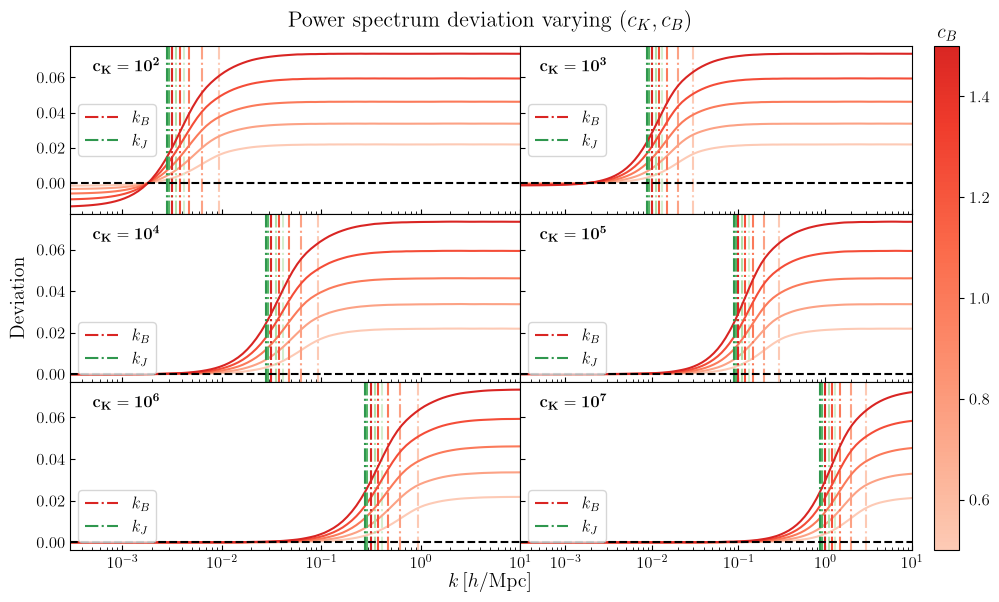

In [ ]:
ncols = 2
nrows = int(np.ceil(len(cK) / ncols))

fig, axs = plt.subplots(
    nrows, 
    ncols, 
    figsize=(10, 2*nrows), 
    sharex=True, 
    sharey=False, 
    squeeze=False
    )

for row in axs:
    for ax in row[1:]:
        ax.sharey(row[0])
        ax.tick_params(axis='y', labelleft=False)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.08, top=0.92, hspace=0, wspace=0)
axs = axs.flatten()

for i, ck in enumerate(cK):
    for j, cb in enumerate(cB):
        if (ck, cb) not in spectra:
            continue
        axs[i].semilogx(k, spectra.deviation(ck, cb), color=cb_colors(cb))

        kB, kJ = spectra.scales(ck, cb)
        last = (j == len(cB) - 1)
        axs[i].axvline(x=kB, color=cb_colors(cb), linestyle='-.', label=r'$k_B$' if last else None)
        axs[i].axvline(x=kJ, color=kJ_colors(cb), linestyle='-.', label=r'$k_J$' if last else None)

    n = np.log10(ck)
    ck_text = fr'$\mathbf{{c_K=10^{{{n:0.0f}}}}}$' if np.isclose(n, round(n)) else fr'$\mathbf{{c_K={ck:g}}}$'
    axs[i].text(0.05, 0.85, ck_text, transform=axs[i].transAxes)
    axs[i].axhline(y=0, color='k', linestyle='--')
    axs[i].legend()

for ax in axs[len(cK):]:
    ax.set_visible(False)

axs[0].set_xlim([k[0], k[-1]])

fig.supxlabel(r"$k\,[h/\mathrm{Mpc}]$")
fig.supylabel("Deviation")
fig.suptitle(r"Power spectrum deviation varying $(c_K,c_B)$", fontsize=16)

cbar = plt.colorbar(cb_colors.mappable, ax=[axs[i] for i in range(ncols-1, len(axs), ncols)],
                    fraction=0.08, shrink=1)
cbar.ax.set_title(r"$c_B$")

for ax in axs:
    ax.tick_params(axis='both', which='both', direction='in')